In [ ]:
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout, Conv2D, MaxPooling2D
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.utils import to_categorical, load_img, img_to_array
from tensorflow.keras.optimizers import SGD
from numpy import argmax
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image

In [ ]:
from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]

Saving Dogs-20261120T191853Z-1-001.zip to Dogs-20261120T191853Z-1-001 (1).zip
Saving Cats-20261120T191851Z-1-001.zip to Cats-20261120T191851Z-1-001 (1).zip


Extracted /content/Cats-20261120T191851Z-1-001 (1).zip to /content/cats_extracted
Extracted /content/Dogs-20261120T191853Z-1-001 (1).zip to /content/dogs_extracted
Class Names: ['Cats']
Train Data Shape: (500, 150, 150, 3)
Test Data Shape: (500, 150, 150, 3)


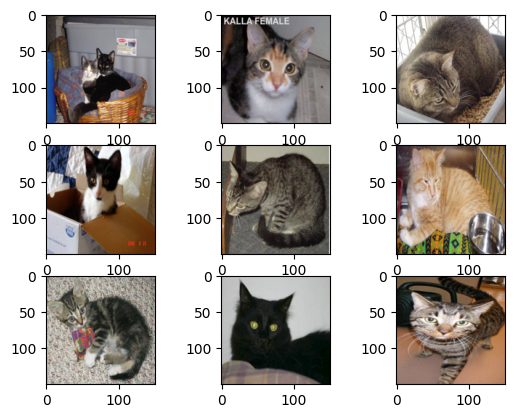

In [6]:
import zipfile
import os
from numpy.random import shuffle
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Function to extract zip files
def extract_zip(zip_path, extract_to):
  with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)
  print(f"Extracted {zip_path} to {extract_to}")

# Extracting the datasets
extract_zip('/content/Cats-20261120T191851Z-1-001 (1).zip', '/content/cats_extracted')
extract_zip('/content/Dogs-20261120T191853Z-1-001 (1).zip', '/content/dogs_extracted')

def load_split(folder, target_size=(150, 150)):
  class_names = sorted(os.listdir(folder))
  images, labels = [], []
  for label, class_name in enumerate(class_names):
    class_dir = os.path.join(folder, class_name)
    if os.path.isdir(class_dir):
      for filename in os.listdir(class_dir):
        # Ensure we only load valid image files and ignore system hidden files (e.g. .DS_Store)
        if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
          try:
            img = Image.open(os.path.join(class_dir, filename)).convert('RGB')
            # Resize the image to ensure consistent shape across all samples
            img = img.resize(target_size)
            images.append(np.array(img))
            labels.append(label)
          except Exception as e:
            print(f"Skipping error image {filename}: {e}")
  x = np.array(images)
  y = np.array(labels).reshape(-1, 1)
  shuffle_order = np.random.permutation(len(x))
  return x[shuffle_order], y[shuffle_order], class_names

# Load datasets from extracted directories (resizing them to 150x150 pixels)
x_train, y_train, class_names = load_split('/content/cats_extracted', target_size=(150, 150))
x_test, y_test, _ = load_split('/content/dogs_extracted', target_size=(150, 150))

print("Class Names:", class_names)
print("Train Data Shape:", x_train.shape)
print("Test Data Shape:", x_test.shape)

for i in range(min(9, len(x_train))):
  plt.subplot(3, 3, 1 + i)
  plt.imshow(x_train[i])
plt.show()

In [7]:
num_classes = len(class_names)

train_size = 8000
test_size = 2000
x_train = x_train[:train_size]
y_train = y_train[:train_size]
x_test = x_test[:test_size]
y_test = y_test[:test_size]

y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

print('x_train shape:', x_train.shape)
print(x_train.shape[0],'train samples')
print(x_test.shape[0], 'test samples')

x_train shape: (500, 150, 150, 3)
500 train samples
500 test samples


In [9]:
model = Sequential()
model.add(Input(shape=(150, 150, 3)))
model.add(Conv2D(16, (3,3), activation='relu', padding='same'))
model.add(Dropout(0.2))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(32, (3,3), activation='relu', padding='same'))
model.add(Dropout(0.2))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dropout(0.2))
model.add(Dense(128, activation='relu', kernel_constraint=max_norm(3)))
model.add(Dropout(0.2))
model.add(Dense(num_classes, activation='softmax'))

opt = SGD(learning_rate=0.01, momentum=0.9, nesterov=False)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 150, 150, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 43808)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 43808)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     5,607,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,612,769 (21.41 MB)

 Trainable params: 5,612,769 (21.41 MB)

 Non-trainable params: 0 (0.00 B)